# Model Explainability: SHAP for the XGBoost Residual Model

**Model:** `models/best_xgboost_residual_model.json` (trained in `model_xgboost_training.ipynb`)
**Data explained:** `data/processed/features-val.csv` (1994–1996). The test set stays untouched until the model is frozen.

## What SHAP explains here

The model does **not** output a risk tier. It predicts **Δ**, the change in sea surface temperature anomaly (SSTA) over the next 3 months, in °C. The forecast and tier are built afterwards:

1. The model predicts Δ from 16 features. ← **SHAP explains this step only**
2. Forecast = today's `ssta` + Δ
3. The forecast is mapped to a risk tier with the calibrated thresholds.

For each row, SHAP splits the predicted Δ into one contribution per feature:

`predicted Δ = base value + sum of SHAP values`

where the base value is the model's average prediction.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
import xgboost as xgb

print(f"SHAP version:    {shap.__version__}")
print(f"XGBoost version: {xgb.__version__}")

SHAP version:    0.54.1
XGBoost version: 3.4.1


## 1. Configuration

In [2]:
DATA_DIR = "../data/processed"
VAL_PATH = os.path.join(DATA_DIR, "features-val.csv")
MODEL_PATH = "../models/best_xgboost_residual_model.json"
FIGURES_DIR = "../reports/figures/shap"

# Must match FEATURES_PHYSICAL in model_xgboost_training.ipynb exactly, including order.
FEATURES_PHYSICAL = [
    "ssta", "ssta_lag1", "ssta_lag2", "ssta_lag3", "ssta_roll3", "ssta_change1", "ssta_change3",
    "basin_ssta", "nino34_ssta", "nino34_ssta_roll3", "basin_zwind_anom", "west_pac_zwind_anom",
    "air_temp_anom", "air_temp_anom_lag1", "zonal_wind_anom", "mer_wind_anom",
]

## 2. Load the validation data and the trained model

Rows are filtered the same way as in the training notebook, so we explain exactly the 1,529 rows the model was scored on.

In [3]:
val_raw = pd.read_csv(VAL_PATH)
val = val_raw.dropna(subset=["target_risk", "target_ssta", "current_risk"]).reset_index(drop=True)
X_val = val[FEATURES_PHYSICAL]

model = xgb.XGBRegressor()
model.load_model(MODEL_PATH)

# The saved model records the features it was trained on. A mismatch here would make every SHAP value wrong.
assert model.get_booster().feature_names == FEATURES_PHYSICAL, "Feature list or order differs from training"

print(f"Validation rows: {len(val):,} ({val['ym'].min()} to {val['ym'].max()})")
print(f"Missing feature values: {X_val.isna().sum().sum():,} (XGBoost and SHAP handle these natively)")

Validation rows: 1,529 (1994-01 to 1996-09)
Missing feature values: 639 (XGBoost and SHAP handle these natively)


## 3. Compute SHAP values

In [4]:
# TreeExplainer computes exact SHAP values for tree models, so this takes seconds.
explainer = shap.TreeExplainer(model)
explanation = explainer(X_val)

print(f"SHAP values shape: {explanation.values.shape} (rows x features)")
print(f"Base value (average predicted Δ): {float(np.mean(explanation.base_values)):+.4f} °C")

SHAP values shape: (1529, 16) (rows x features)
Base value (average predicted Δ): +0.0119 °C


## 4. Sanity check: SHAP values add up to the prediction

For every row, base value + sum of SHAP values must equal the model's predicted Δ. If this fails, the explanation does not describe this model.

In [5]:
pred_delta = model.predict(X_val)
reconstructed = explanation.base_values + explanation.values.sum(axis=1)
max_error = np.abs(reconstructed - pred_delta).max()

assert max_error < 1e-4, f"Additivity check failed: max error {max_error}"
print(f"Additivity check passed: max error {max_error:.2e} °C")

# The same check, row by row, for the first few rows
pd.DataFrame({
    "site_id": val["site_id"].head(),
    "ym": val["ym"].head(),
    "base value": explanation.base_values[:5],
    "sum of SHAP": explanation.values[:5].sum(axis=1),
    "base + SHAP": reconstructed[:5],
    "predicted Δ": pred_delta[:5],
}).round(4)

Additivity check passed: max error 1.79e-07 °C


,site_id,ym,base value,sum of SHAP,base + SHAP,predicted Δ
0,-2_-110,1994-01,0.0119,-0.4843,-0.4724,-0.4724
1,-2_-110,1994-02,0.0119,0.1218,0.1338,0.1338
2,-2_-110,1994-03,0.0119,0.0650,0.0769,0.0769
3,-2_-110,1994-04,0.0119,0.2108,0.2227,0.2227
4,-2_-110,1994-05,0.0119,0.1495,0.1615,0.1615


## 5. First look: average impact per feature

Mean |SHAP| is how far, on average, each feature moves the predicted Δ (in °C). This is the table behind the bar plot made in the next section.

In [6]:
mean_abs_shap = (
    pd.Series(np.abs(explanation.values).mean(axis=0), index=FEATURES_PHYSICAL, name="mean |SHAP| (°C)")
    .sort_values(ascending=False)
)
unused = mean_abs_shap[mean_abs_shap == 0].index.tolist()

print(f"Features the model uses: {len(FEATURES_PHYSICAL) - len(unused)} of {len(FEATURES_PHYSICAL)}")
print(f"Never used by any tree: {unused}")
mean_abs_shap.round(4).to_frame()

Features the model uses: 8 of 16
Never used by any tree: ['ssta_roll3', 'ssta_change1', 'basin_ssta', 'nino34_ssta', 'nino34_ssta_roll3', 'air_temp_anom_lag1', 'zonal_wind_anom', 'mer_wind_anom']


,mean |SHAP| (°C)
ssta,0.1242
ssta_lag3,0.0614
west_pac_zwind_anom,0.0412
air_temp_anom,0.0038
ssta_lag2,0.0035
basin_zwind_anom,0.0030
ssta_lag1,0.0021
ssta_change3,0.0019
ssta_roll3,0.0000
ssta_change1,0.0000


## 6. Shared plotting helpers

These functions work for any tree model explained with `shap.TreeExplainer` (XGBoost, LightGBM), so every model gets the same set of figures. Each model's figures go in their own folder: `reports/figures/shap/<model_name>/`.

- `save_summary_plots` saves the bar plot, the beeswarm and one dependence plot per top feature.
- `save_waterfall` saves the explanation of a single prediction.

In [7]:
def _save_current_figure(path):
    """Save the figure SHAP just drew, then close it so figures don't pile up in memory."""
    fig = plt.gcf()
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print(f"Saved {path}")


def save_summary_plots(explanation, model_name, output_label, n_dependence=4):
    """Save the bar plot, the beeswarm and dependence plots for the top features.

    explanation:  a shap.Explanation for the rows being explained
    model_name:   folder name under FIGURES_DIR, e.g. "xgboost"
    output_label: what the model predicts, used in titles, e.g. "predicted 3-month change Δ (°C)"
    """
    out_dir = os.path.join(FIGURES_DIR, model_name)
    os.makedirs(out_dir, exist_ok=True)
    n_features = explanation.values.shape[1]

    shap.plots.bar(explanation, max_display=n_features, show=False)
    plt.title(f"{model_name}: average impact on {output_label}")
    _save_current_figure(os.path.join(out_dir, "bar.png"))

    shap.plots.beeswarm(explanation, max_display=n_features, show=False)
    plt.title(f"{model_name}: how each feature pushes the {output_label}")
    _save_current_figure(os.path.join(out_dir, "beeswarm.png"))

    mean_abs = np.abs(explanation.values).mean(axis=0)
    top_features = [explanation.feature_names[i] for i in np.argsort(mean_abs)[::-1][:n_dependence]]
    for feature in top_features:
        shap.plots.scatter(explanation[:, feature], show=False)
        plt.title(f"{model_name}: effect of {feature}")
        _save_current_figure(os.path.join(out_dir, f"dependence_{feature}.png"))


def save_waterfall(explanation, row, model_name, file_stem, title):
    """Save the waterfall plot explaining a single row's prediction."""
    out_dir = os.path.join(FIGURES_DIR, model_name)
    os.makedirs(out_dir, exist_ok=True)
    shap.plots.waterfall(explanation[row], max_display=10, show=False)
    plt.title(title, fontsize=10)
    _save_current_figure(os.path.join(out_dir, f"waterfall_{file_stem}.png"))

## 7. XGBoost: overall importance and direction

- **Bar plot:** average |SHAP| per feature, i.e. which features matter most overall.
- **Beeswarm:** one dot per validation row. Red means a high feature value, blue a low one; dots to the right push the predicted change warmer, dots to the left push it cooler.
- **Dependence plots:** for each of the top 4 features, the feature's value (x-axis) against its SHAP value (y-axis).

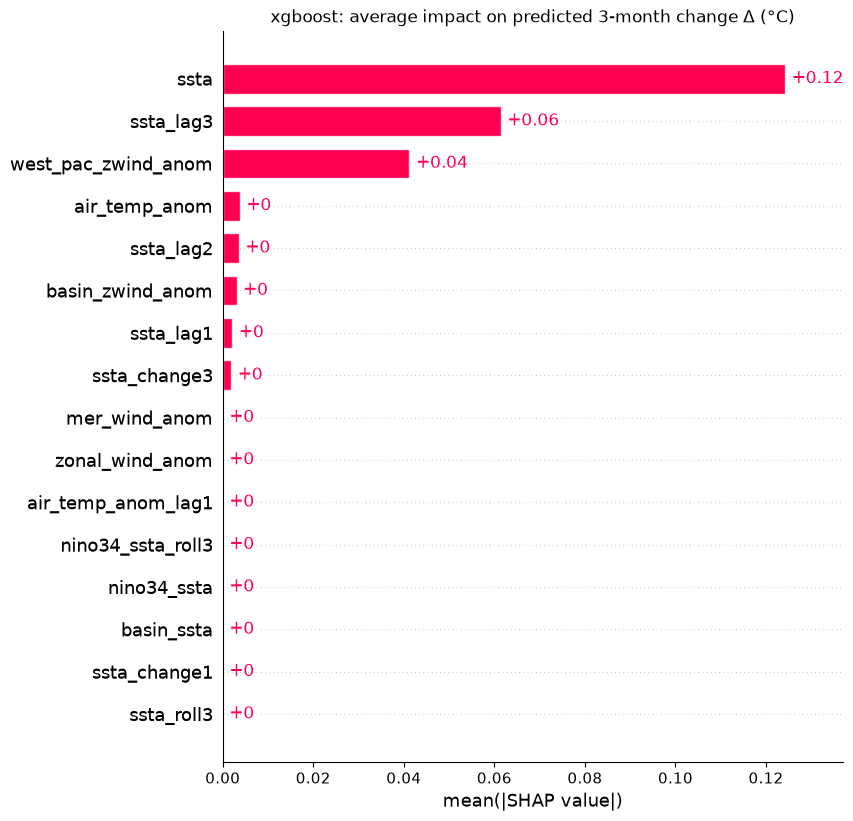

Saved ../reports/figures/shap/xgboost/bar.png


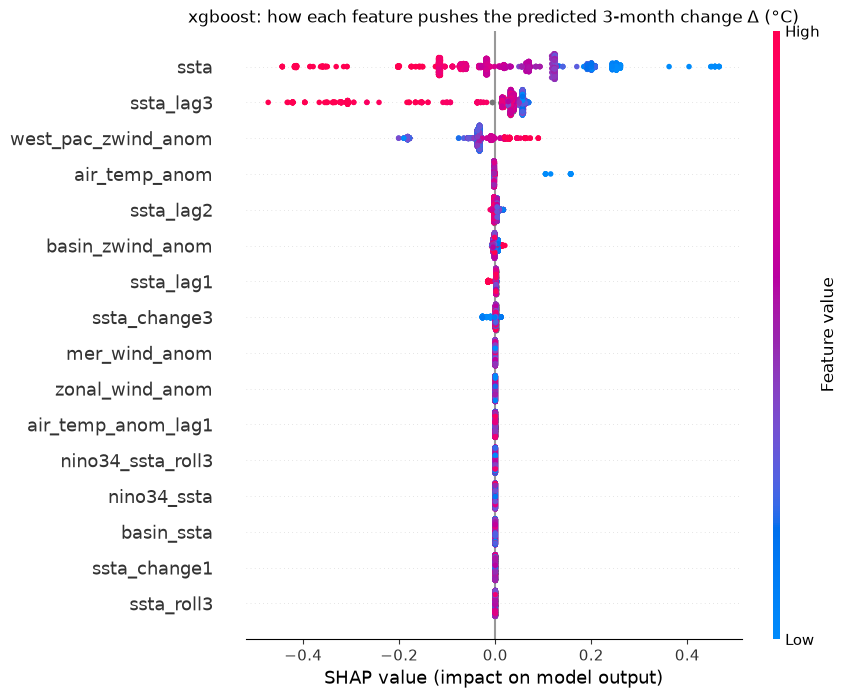

Saved ../reports/figures/shap/xgboost/beeswarm.png


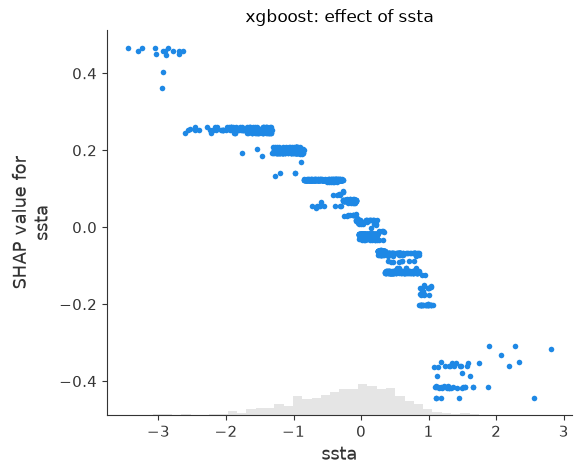

Saved ../reports/figures/shap/xgboost/dependence_ssta.png


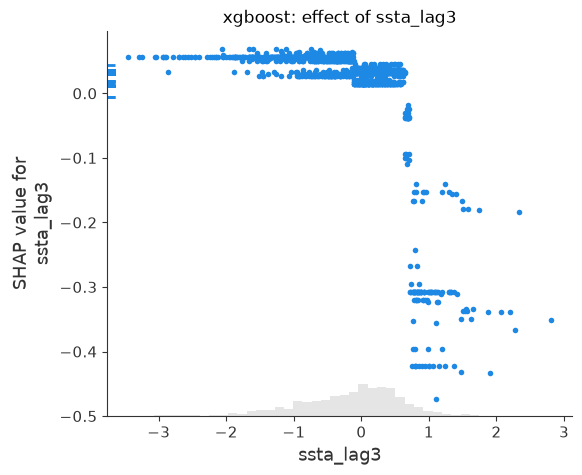

Saved ../reports/figures/shap/xgboost/dependence_ssta_lag3.png


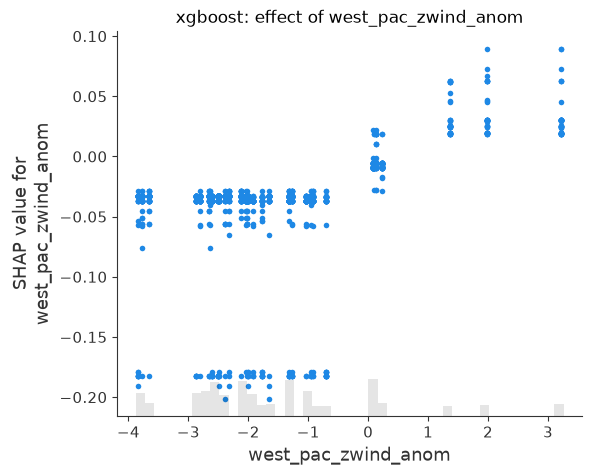

Saved ../reports/figures/shap/xgboost/dependence_west_pac_zwind_anom.png


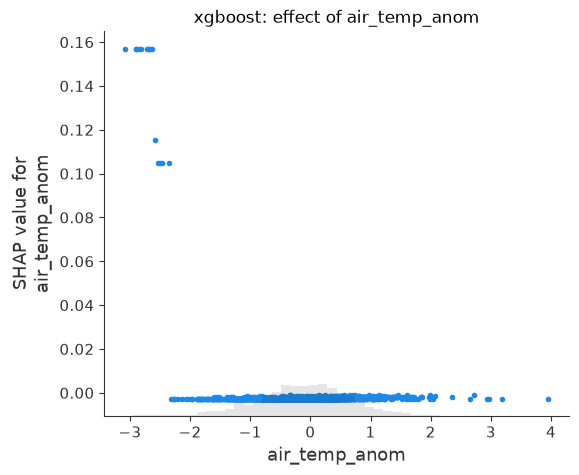

Saved ../reports/figures/shap/xgboost/dependence_air_temp_anom.png


In [8]:
save_summary_plots(explanation, model_name="xgboost", output_label="predicted 3-month change Δ (°C)")

## 8. XGBoost: explaining single forecasts

Each waterfall starts at the base value (the average predicted Δ) and adds each feature's push until it reaches this row's predicted Δ. The title shows how that Δ becomes the forecast and tier.

The three examples are verified validation rows:

| Example | Why it was chosen |
| --- | --- |
| `-2_-125`, 1995-11 | Correct Extreme Cool warning |
| `0_-170`, 1994-08 | Correct Extreme Warm warning |
| `0_-170`, 1994-07 | Missed Extreme Warm: forecast Moderate Warm, actual Extreme Warm |

Note: the `0_-110` walkthrough in `docs/MODEL_XGBOOST_TRAINING.md` (ssta −1.25, Δ −0.18, actual −1.62) does not match any validation row, so it is not reused here.

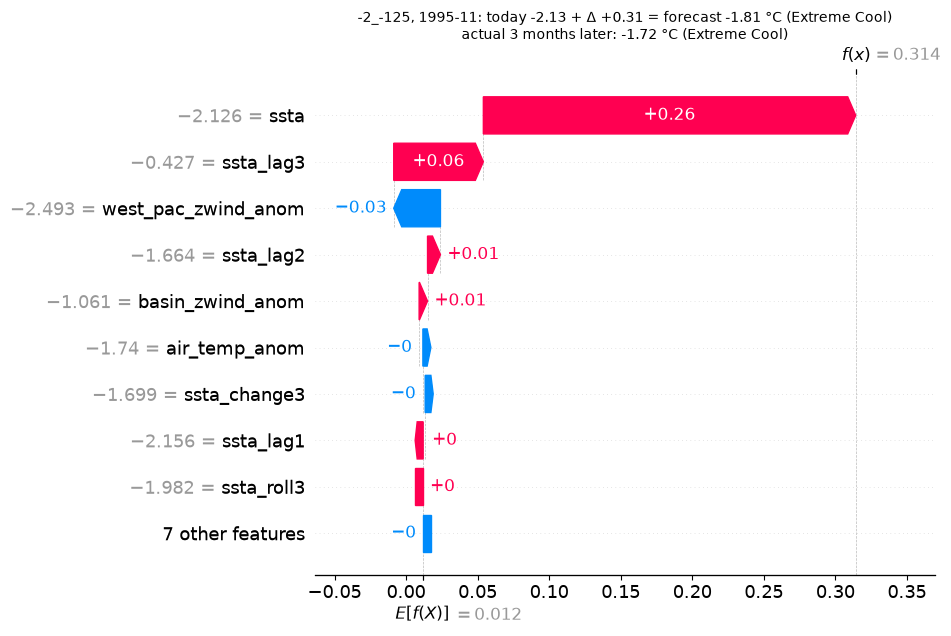

Saved ../reports/figures/shap/xgboost/waterfall_correct_extreme_cool.png


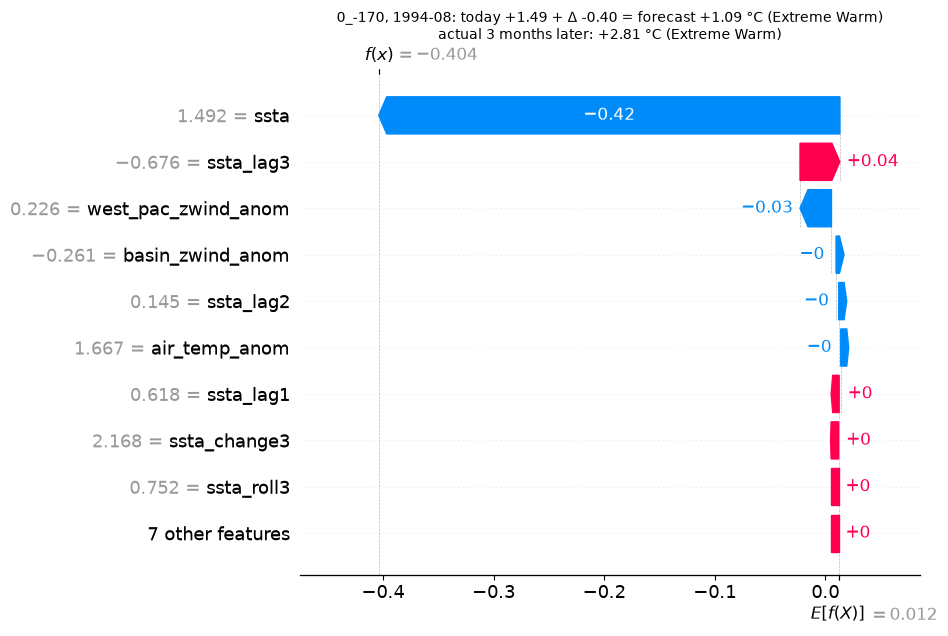

Saved ../reports/figures/shap/xgboost/waterfall_correct_extreme_warm.png


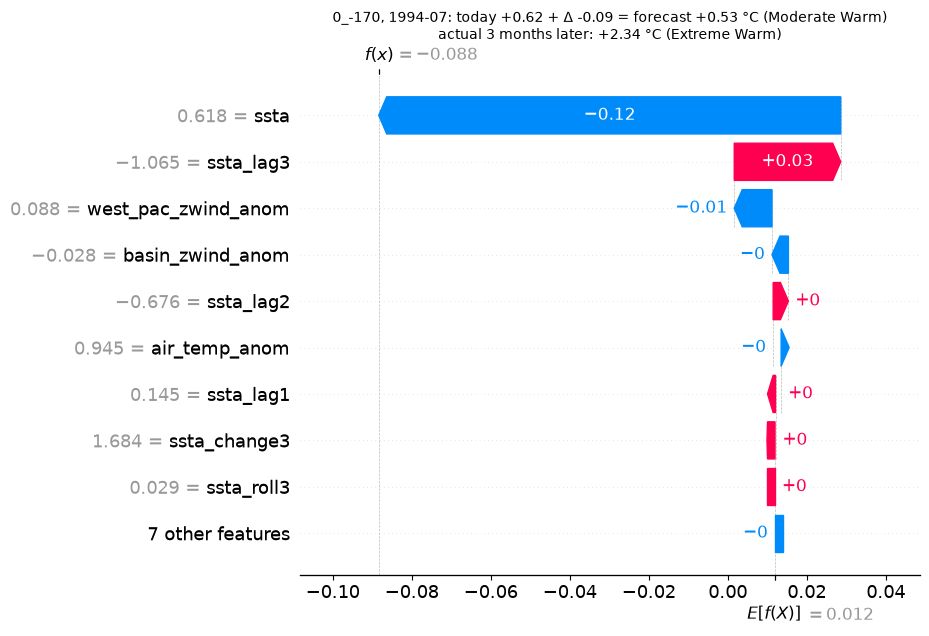

Saved ../reports/figures/shap/xgboost/waterfall_missed_extreme_warm.png


In [9]:
def classify_calibrated(anomaly):
    """Calibrated tier thresholds, copied from model_xgboost_training.ipynb."""
    if anomaly >= 1.0:  return "Extreme Warm"
    if anomaly >= 0.35: return "Moderate Warm"
    if anomaly <= -1.1: return "Extreme Cool"
    if anomaly <= -0.4: return "Moderate Cool"
    return "Neutral"


val["pred_delta"] = pred_delta
val["forecast_ssta"] = val["ssta"] + val["pred_delta"]
val["forecast_tier"] = val["forecast_ssta"].map(classify_calibrated)

EXAMPLES = [
    ("-2_-125", "1995-11", "correct_extreme_cool"),
    ("0_-170", "1994-08", "correct_extreme_warm"),
    ("0_-170", "1994-07", "missed_extreme_warm"),
]

for site_id, ym, file_stem in EXAMPLES:
    row = val.index[(val["site_id"] == site_id) & (val["ym"] == ym)][0]
    r = val.loc[row]
    title = (
        f"{site_id}, {ym}: today {r['ssta']:+.2f} + Δ {r['pred_delta']:+.2f} = forecast {r['forecast_ssta']:+.2f} °C "
        f"({r['forecast_tier']})\nactual 3 months later: {r['target_ssta']:+.2f} °C ({r['target_risk']})"
    )
    save_waterfall(explanation, row, model_name="xgboost", file_stem=file_stem, title=title)

## 9. Model checks

These checks follow "Using SHAP to improve the model" in the team's planning doc.

In [10]:
# Check 1: no location shortcuts. lat/lon were removed after the model memorized buoy coordinates.
location_features = [f for f in FEATURES_PHYSICAL if f in ("lat", "lon", "site_id")]
print(f"Location features in the model: {location_features or 'none'}")

# Check 2: direction of each used feature's effect.
# Correlation between a feature's value and its SHAP value: positive means a higher value pushes the forecast warmer.
shap_df = pd.DataFrame(explanation.values, columns=FEATURES_PHYSICAL)
used = mean_abs_shap[mean_abs_shap > 0].index
direction = pd.DataFrame({
    "mean |SHAP| (°C)": mean_abs_shap[used].round(4),
    "value vs SHAP correlation": [
        round(np.corrcoef(X_val[f][X_val[f].notna()], shap_df[f][X_val[f].notna()])[0, 1], 2) for f in used
    ],
})
direction["higher value pushes Δ"] = np.where(direction["value vs SHAP correlation"] > 0, "warmer", "cooler")
direction

Location features in the model: none


,mean |SHAP| (°C),value vs SHAP correlation,higher value pushes Δ
ssta,0.1242,-0.95,cooler
ssta_lag3,0.0614,-0.57,cooler
west_pac_zwind_anom,0.0412,0.46,warmer
air_temp_anom,0.0038,-0.31,cooler
ssta_lag2,0.0035,-0.72,cooler
basin_zwind_anom,0.0030,-0.16,cooler
ssta_lag1,0.0021,-0.45,cooler
ssta_change3,0.0019,0.42,warmer


In [11]:
# Check 3: features with no effect at all
print(f"Unused features ({len(unused)}): {unused}")

# Check 4: what limits extreme-event detection?
true_delta = val["target_ssta"] - val["ssta"]
print(f"\nPredicted Δ ranges from {val['pred_delta'].min():+.2f} to {val['pred_delta'].max():+.2f} °C "
      f"(std {val['pred_delta'].std():.2f})")
print(f"Actual Δ ranges from {true_delta.min():+.2f} to {true_delta.max():+.2f} °C (std {true_delta.std():.2f})")

extreme_warm = val[val["target_risk"] == "Extreme Warm"]
print(f"\nExtreme Warm rows: {len(extreme_warm)}; predicted Δ was negative (cooling) for "
      f"{(extreme_warm['pred_delta'] < 0).sum()} of them")
extreme_warm[["site_id", "ym", "ssta", "pred_delta", "forecast_ssta", "forecast_tier", "target_ssta"]].round(2)

Unused features (8): ['ssta_roll3', 'ssta_change1', 'basin_ssta', 'nino34_ssta', 'nino34_ssta_roll3', 'air_temp_anom_lag1', 'zonal_wind_anom', 'mer_wind_anom']

Predicted Δ ranges from -0.87 to +0.70 °C (std 0.22)
Actual Δ ranges from -5.60 to +2.95 °C (std 0.78)

Extreme Warm rows: 17; predicted Δ was negative (cooling) for 15 of them


,site_id,ym,ssta,pred_delta,forecast_ssta,forecast_tier,target_ssta
191,-2_156,1995-05,0.67,-0.12,0.56,Moderate Warm,1.62
196,-2_156,1995-10,0.49,-0.55,-0.06,Neutral,1.51
197,-2_156,1995-11,0.19,-0.54,-0.35,Neutral,1.53
203,-2_156,1996-05,0.57,-0.58,-0.01,Neutral,1.65
414,-5_156,1995-10,0.54,-0.55,-0.01,Neutral,1.54
415,-5_156,1995-11,0.32,-0.06,0.26,Neutral,1.88
416,-5_156,1995-12,0.37,-0.12,0.26,Neutral,1.65
628,0_-110,1994-07,-0.86,0.23,-0.64,Moderate Cool,1.74
660,0_-125,1994-08,0.57,-0.11,0.46,Moderate Warm,2.19
661,0_-125,1994-09,0.80,-0.19,0.62,Moderate Warm,1.90


## 10. Findings (validation set, 1994–1996)

1. **The model is mostly "today's anomaly, pulled back toward normal."** `ssta` has by far the biggest impact (0.12 °C on average, twice the next feature), and its effect runs in reverse: a warm reading today pushes the predicted change cooler, and a cold reading pushes it warmer (value vs SHAP correlation −0.95). This matches ocean physics, since anomalies tend to fade over time.
2. **Western Pacific winds are the main early-warning signal from outside the buoy itself.** Higher `west_pac_zwind_anom` (westerly wind anomalies) pushes forecasts warmer (correlation +0.46). Westerly wind bursts in the western Pacific are a known trigger for El Niño, so the model learned a physically sensible signal.
3. **Only 8 of the 16 features are used.** The model is deliberately small (40 trees, depth 2), and the Niño 3.4 and basin-wide SSTA features carry information it already gets from `ssta`. A reviewer may ask why the standard El Niño index (`nino34_ssta`) has zero impact; this is the answer.
4. **No location shortcut.** No latitude, longitude or site features are in the model, so the coordinate-memorizing problem from earlier experiments is gone.
5. **The model can't forecast fast warming, which is why it misses Extreme Warm events.** Predicted changes stay between −0.87 and +0.70 °C (std 0.22), while actual changes reach +2.95 °C (std 0.78). For 15 of the 17 Extreme Warm rows, the model predicted cooling. The pull-back-to-normal effect in finding 1 dominates exactly when an El Niño is building. In the missed example (`0_-170`, 1994-07), the buoy had already warmed 1.68 °C over the previous 3 months (`ssta_change3`), but the model gave that momentum almost no weight. Momentum features are a candidate to strengthen (see the interaction features on the XGBoost doc's roadmap).